# Phase 4 — Exploratory Data Analysis

This notebook analyzes the cleaned USGS 2025 development dataset produced by Phase 3. It calculates descriptive statistics and creates exploratory figures for magnitude, depth, time, geography, and province assignments.

These results are provisional development findings. They are not earthquake predictions, current-activity claims, or final PHIVOLCS research conclusions.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
PROJECT_ROOT = next(path for path in candidates if (path / 'backend' / 'app').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'backend'))

from app.analysis.eda import (
    calculate_statistics,
    create_visualizations,
    export_statistical_results,
    load_cleaned_dataset,
    write_findings_document,
)

INPUT_PATH = PROJECT_ROOT / 'backend' / 'data' / 'processed' / 'cleaned_usgs_2025.csv'
OUTPUT_DIR = PROJECT_ROOT / 'docs' / 'eda'
FIGURE_DIR = OUTPUT_DIR / 'figures'
STATISTICS_DIR = OUTPUT_DIR / 'statistics'
print(f'Input: {INPUT_PATH}')
print(f'Output: {OUTPUT_DIR}')

Input: C:\Users\Admin\OneDrive\Documents\earthquake_hotspot_finder\backend\data\processed\cleaned_usgs_2025.csv
Output: C:\Users\Admin\OneDrive\Documents\earthquake_hotspot_finder\docs\eda


## Load and verify the analysis input

The notebook reads the cleaned Phase 3 output. It does not edit the raw USGS CSV or the ADM2 boundary file.

In [2]:
frame = load_cleaned_dataset(INPUT_PATH)
print(f'Records: {len(frame):,}')
print(f'Columns: {len(frame.columns):,}')
print(f'Date coverage: {frame.occurred_at.min()} to {frame.occurred_at.max()}')
display(frame[['source_event_id', 'occurred_at', 'latitude', 'longitude', 'depth_km', 'magnitude', 'province_name', 'geographic_assignment_status']].head())

Records: 794
Columns: 55
Date coverage: 2025-01-01 18:39:33.615000+00:00 to 2025-12-31 17:30:42.385000+00:00


,source_event_id,occurred_at,latitude,longitude,depth_km,magnitude,province_name,geographic_assignment_status
0,us6000pjry,2025-01-01 18:39:33.615+00:00,11.7570,125.9354,10.000,4.6,NaN,offshore_or_unassigned
1,us6000pgxf,2025-01-01 19:25:08.907+00:00,21.7632,121.7787,10.000,4.0,NaN,outside_study_scope_candidate
2,us6000pkew,2025-01-04 05:42:58.606+00:00,7.3151,123.6156,10.000,4.1,NaN,offshore_or_unassigned
3,us6000phut,2025-01-04 13:57:33.463+00:00,4.7057,126.4071,87.575,4.4,NaN,offshore_or_unassigned
4,us6000pkfc,2025-01-04 19:31:05.239+00:00,11.6865,126.0581,10.000,4.3,NaN,offshore_or_unassigned


## Basic statistics

In [3]:
statistics = calculate_statistics(frame)
numeric_summary = pd.DataFrame(statistics['numeric_summary']).T
display(numeric_summary)
display(pd.DataFrame([
    {'measure': 'Records', 'value': statistics['record_count']},
    {'measure': 'Assigned provinces', 'value': statistics['assigned_province_count']},
    {'measure': 'Event start (UTC)', 'value': statistics['date_min_utc']},
    {'measure': 'Event end (UTC)', 'value': statistics['date_max_utc']},
]))

,count,min,q1,median,mean,q3,max,std
magnitude,794.0,4.0000,4.300000,4.50000,4.568388,4.700000,7.4000,0.377114
depth_km,794.0,8.4010,10.000000,35.00000,61.741865,78.284750,634.6640,94.605698
latitude,794.0,4.0214,6.598375,7.71565,9.609323,11.225100,21.9585,4.513386
longitude,794.0,116.7771,123.908700,126.05595,125.060835,126.827775,127.9340,2.304621


,measure,value
0,Records,794
1,Assigned provinces,37
2,Event start (UTC),2025-01-01T18:39:33.615000+00:00
3,Event end (UTC),2025-12-31T17:30:42.385000+00:00


## Magnitude distribution

In [4]:
display(pd.DataFrame(statistics['magnitude_distribution']))
display(pd.Series(statistics['magnitude_type_counts'], name='records').rename_axis('magnitude_type').to_frame())

,magnitude_bin,earthquake_count
0,<4.5,356
1,4.5–<5.0,344
2,5.0–<5.5,70
3,5.5–<6.0,17
4,6.0–<6.5,4
5,6.5–<7.0,2
6,≥7.0,1


,records
magnitude_type,
mb,724
mww,67
mwr,3


## Depth distribution

In [5]:
display(pd.DataFrame(statistics['depth_distribution']))

,depth_bin,earthquake_count
0,Shallow (<70 km),557
1,Intermediate (70–<300 km),213
2,Deep (≥300 km),24


## Temporal distribution

In [6]:
monthly_activity = pd.DataFrame(statistics['monthly_activity'])
display(monthly_activity)

,month,earthquake_count
0,2025-01,53
1,2025-02,42
2,2025-03,53
3,2025-04,42
4,2025-05,54
5,2025-06,50
6,2025-07,47
7,2025-08,32
8,2025-09,64
9,2025-10,234


## Geographical and province-level distribution

In [7]:
assignment_table = pd.DataFrame(
    statistics['geographic_assignment_counts'].items(),
    columns=['geographic_assignment_status', 'records'],
)
display(assignment_table)
display(pd.DataFrame(statistics['province_activity']).head(15))

,geographic_assignment_status,records
0,offshore_or_unassigned,652
1,assigned,120
2,outside_study_scope_candidate,22


,province_name,earthquake_count
0,Cebu,16
1,Ilocos Norte,7
2,Surigao del Sur,7
3,Surigao del Norte,6
4,Leyte,6
5,Davao Oriental,6
6,Cotabato,5
7,Abra,5
8,Agusan del Sur,4
9,Occidental Mindoro,4


## Generate and display exploratory visualizations

The geographical scatter plot uses longitude and latitude from the records. Province assignment counts only include points intersecting an ADM2 polygon; no nearest-province fallback is applied.

magnitude_distribution.png


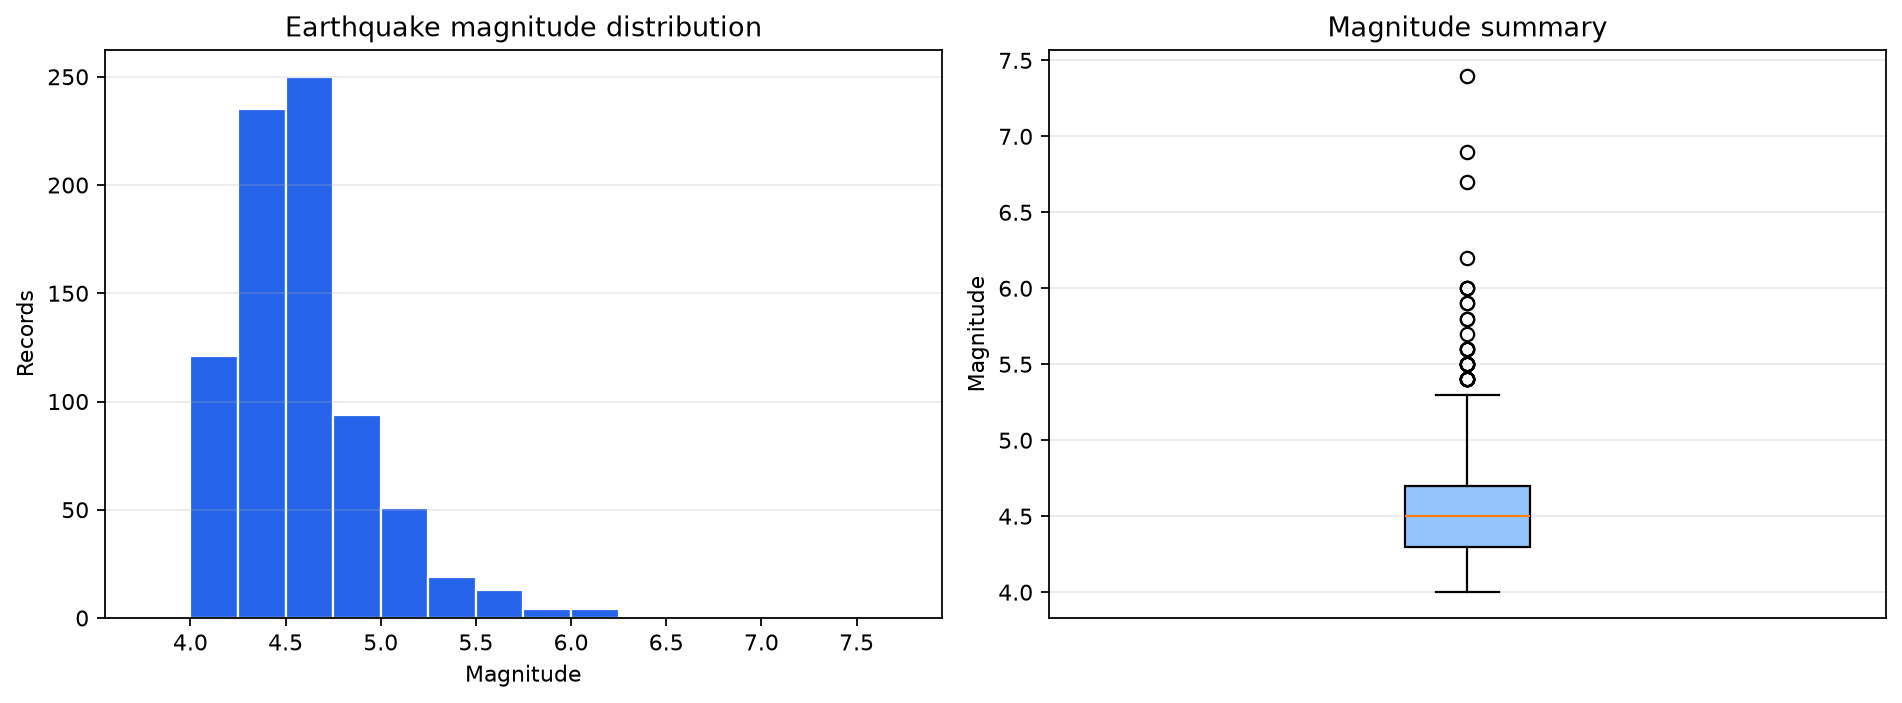

depth_distribution.png


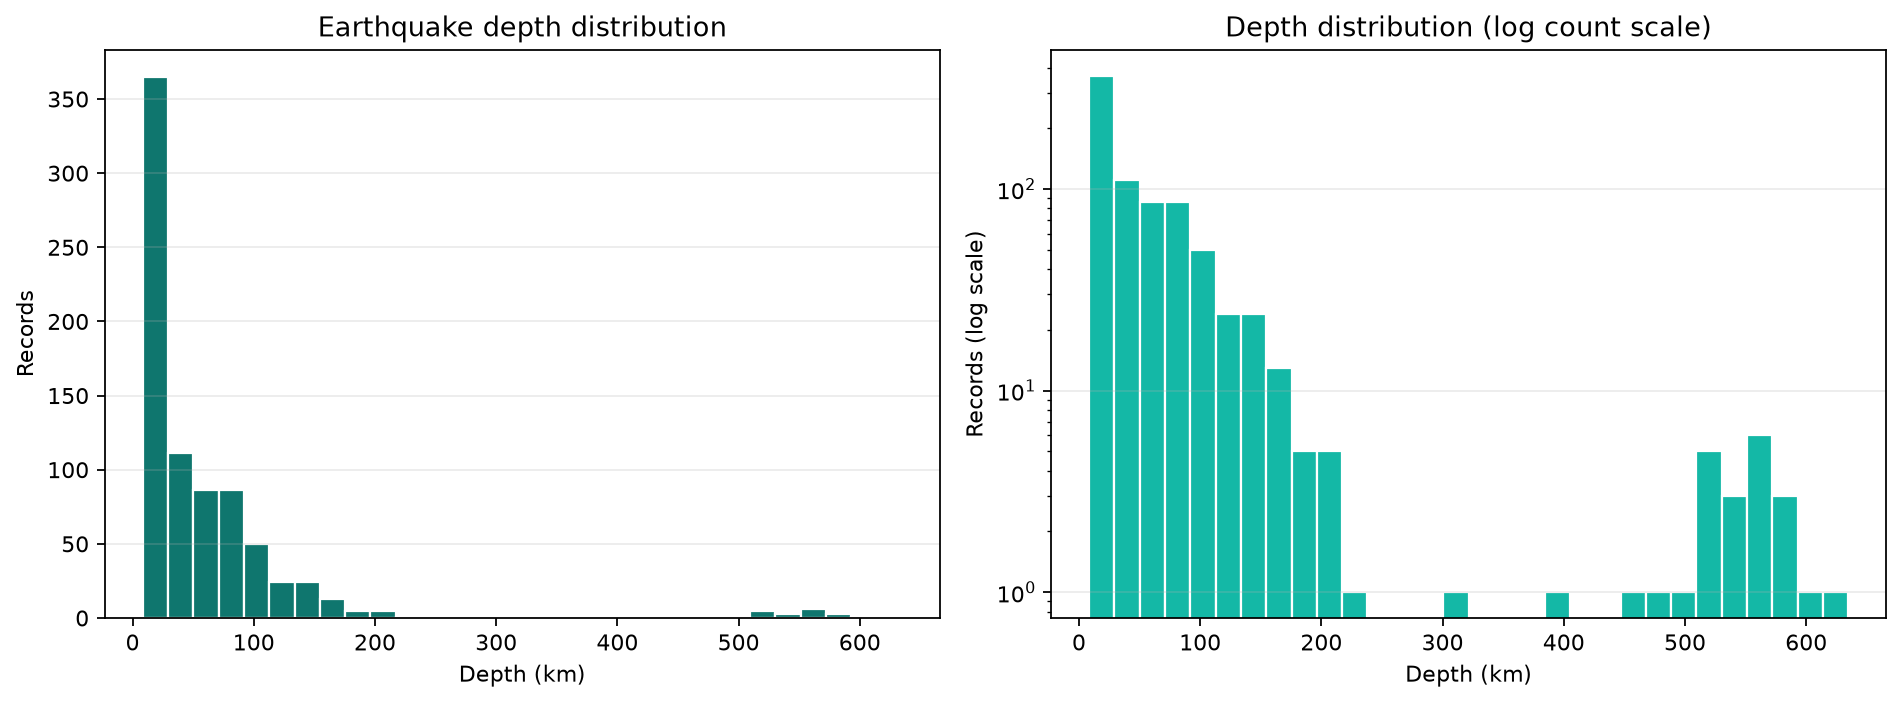

monthly_activity.png


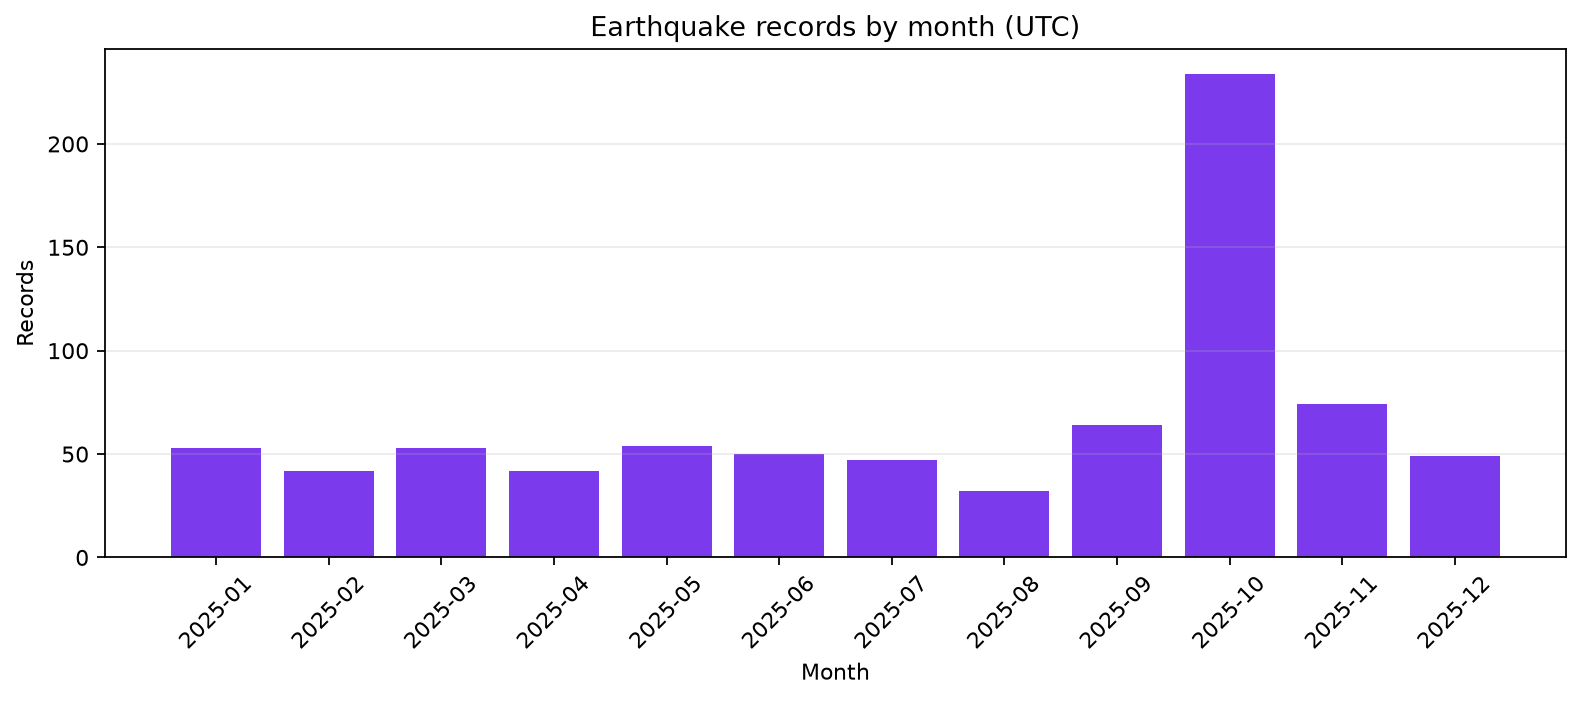

geographical_distribution.png


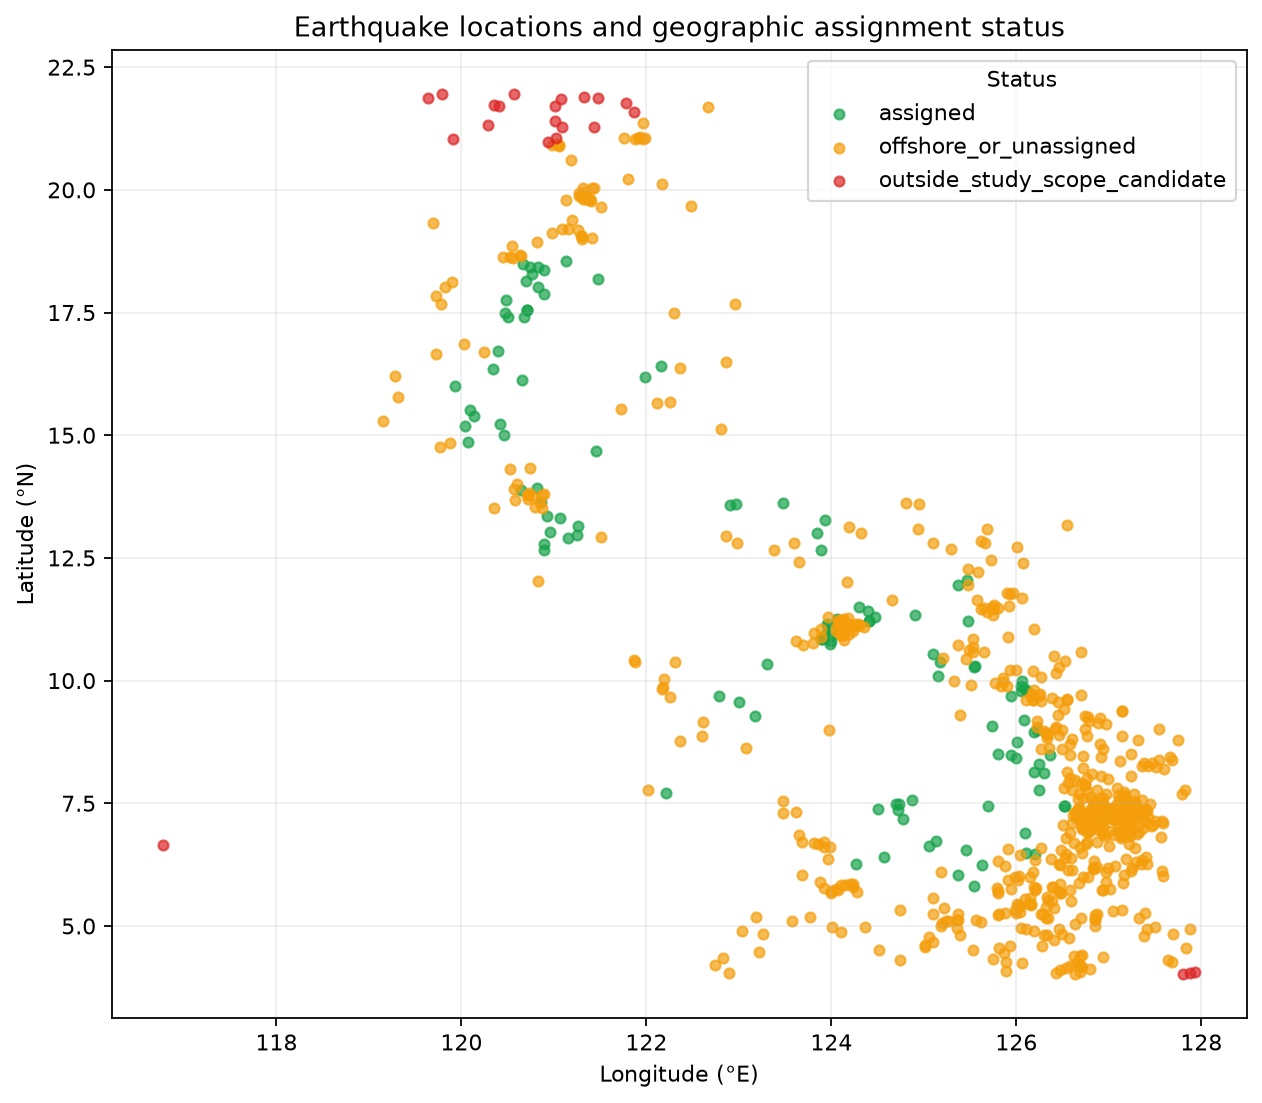

province_activity.png


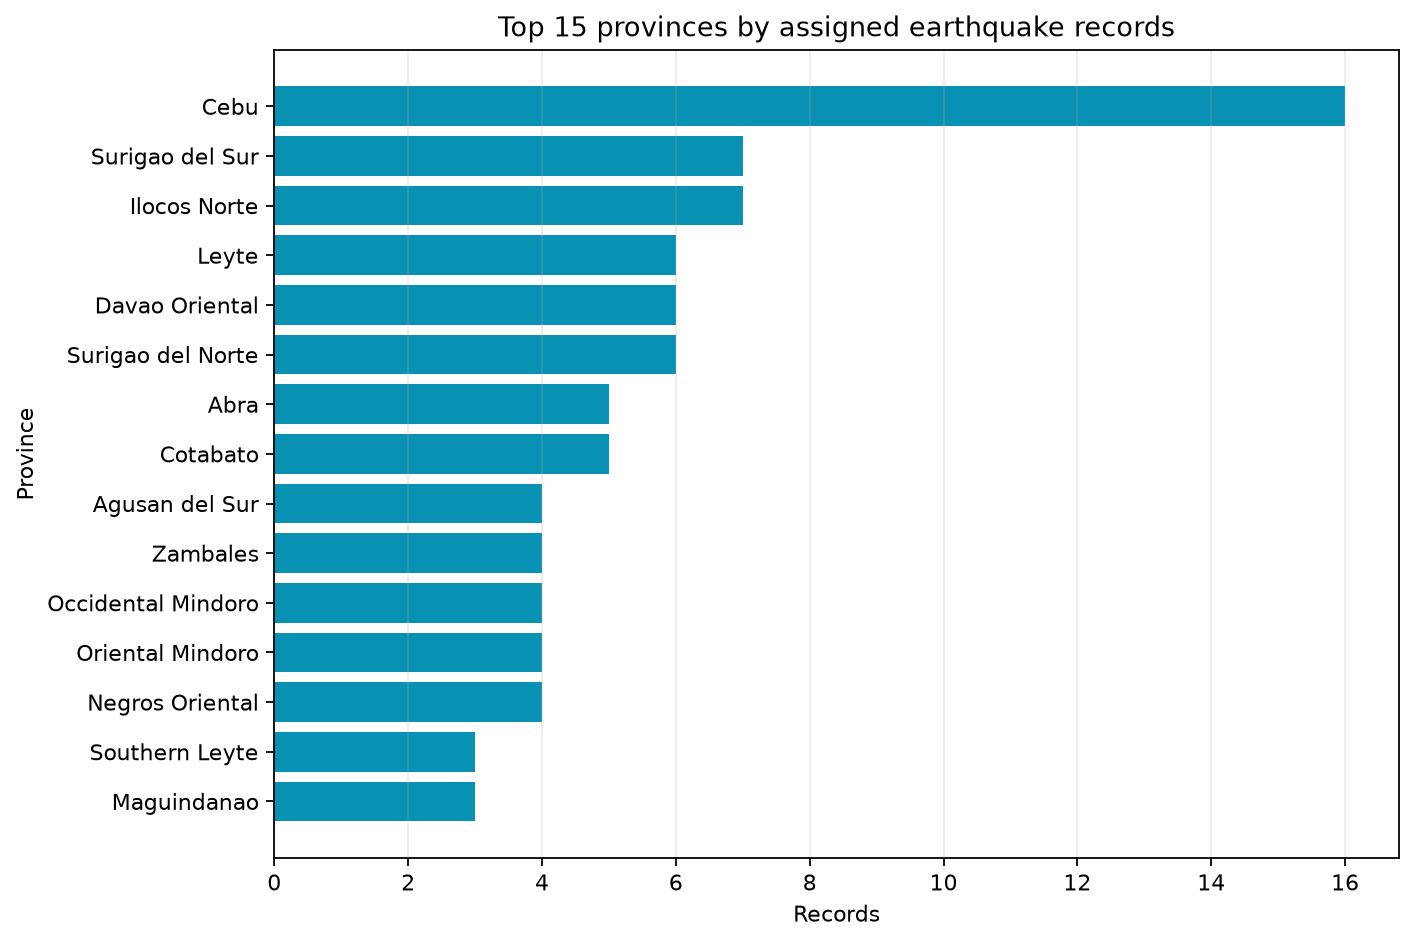

magnitude_vs_depth.png


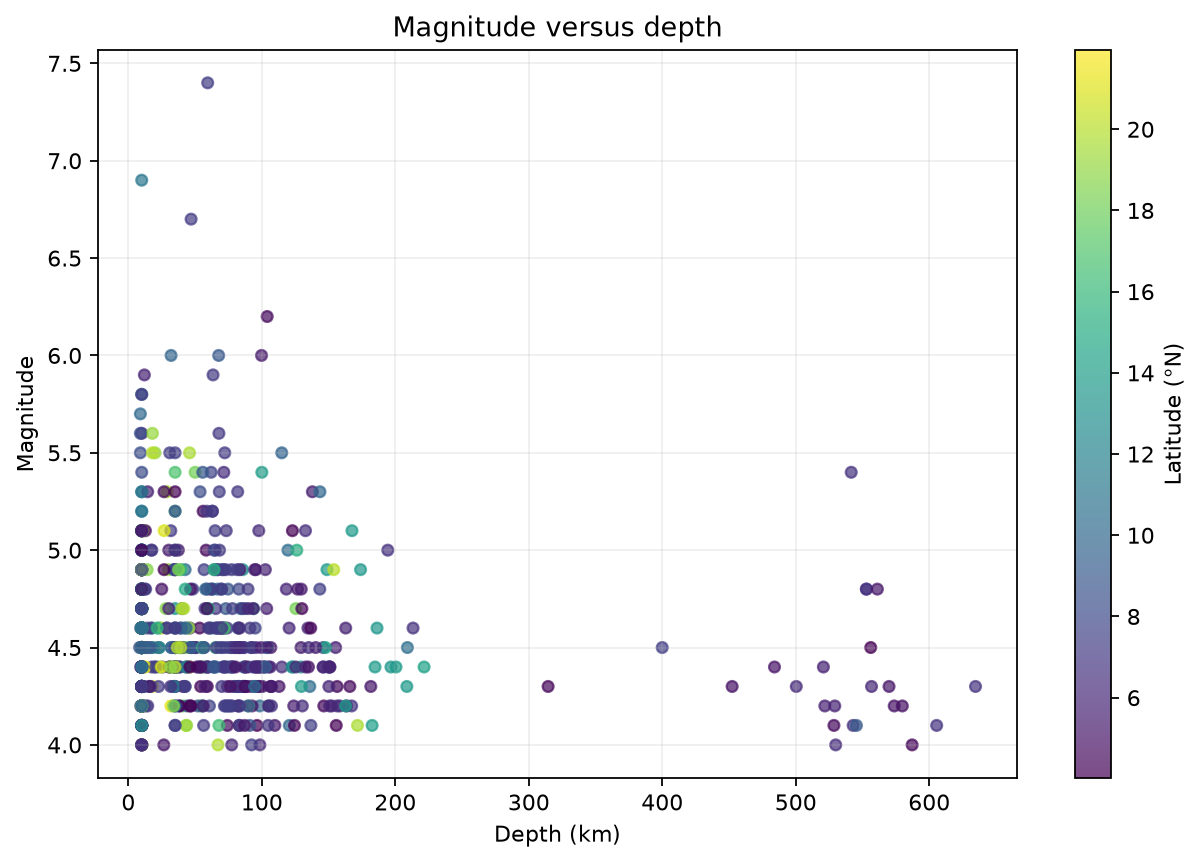

In [8]:
statistical_paths = export_statistical_results(frame, STATISTICS_DIR)
figure_paths = create_visualizations(frame, FIGURE_DIR)
findings_path = OUTPUT_DIR / 'EDA_FINDINGS.md'
write_findings_document(frame, statistics, findings_path, figure_paths)

for path in figure_paths.values():
    print(path.name)
    display(Image(filename=str(path), width=700))

## Interpretation boundaries

The figures describe this one-year USGS development dataset. They do not prove that one province is intrinsically more hazardous, do not estimate future earthquake probability, and should not be presented as final findings until the final research catalogue and spatial-inclusion policy have been approved.